# ploynomial regression
it is used to overcome underfitting error in linear regression

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [3]:
import pandas as pd
data=pd.DataFrame({
    "study_hours":[1,2,3,4,5],
    "marks":[10,25,55,90,130]
})
data

,study_hours,marks
0,1,10
1,2,25
2,3,55
3,4,90
4,5,130


In [4]:
x=data[["study_hours"]]
y=data["marks"]

In [5]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.40,random_state=42)

In [6]:
poly=PolynomialFeatures(degree=2)
x_train_poly=poly.fit_transform(x_train)
x_test_poly=poly.transform(x_test)

In [7]:
model=LinearRegression()
model.fit(x_train_poly,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0. ,5.83,4.17]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.842e-14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,2
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[10.83, 0.32,-0. ]"


In [8]:
y_train_pred=model.predict(x_train_poly)
y_test_pred=model.predict(x_test_poly)

In [9]:
y_test_pred

array([ 28.33333333, 133.33333333])

In [10]:
train_mse=mean_squared_error(y_train,y_train_pred)
test_mse=mean_squared_error(y_test,y_test_pred)
print("tarining mse :",train_mse)
print("testing mse :",test_mse)

tarining mse : 1.5146129380243427e-28
testing mse : 11.111111111111091


/home/user/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


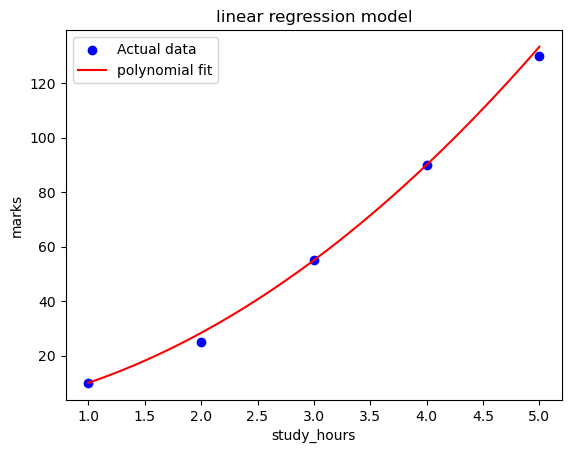

In [12]:
plt.figure()
plt.scatter(x,y,color="blue",label="Actual data")
x_line=np.linspace(min(x["study_hours"]),max(x["study_hours"]),100).reshape(-1,1)
y_line=model.predict(poly.transform(x_line))
plt.plot(x_line,y_line,color="red",label="polynomial fit")
plt.xlabel("study_hours")
plt.ylabel("marks")
plt.title("linear regression model")
plt.legend()
plt.show()